In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# momentum

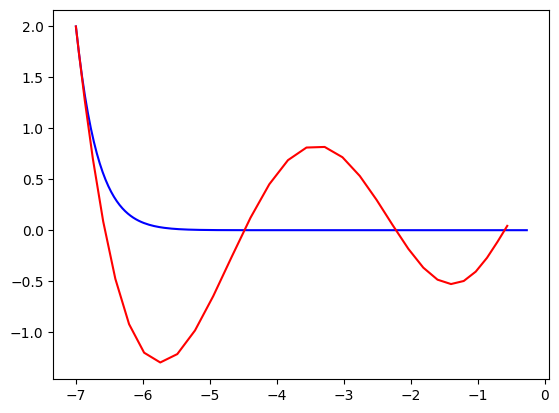

In [ ]:
# 定义函数
def f(x):
    return 0.05 * (x[0] ** 2) + x[1] ** 2

# 实现梯度下降法
def gradient_descent(x, optimizer, num_iters):
    # 拷贝当前x的值，放入列表中
    x_arr = x.detach().numpy().copy()
    for i in range(num_iters):
        # 前向传播
        y = f(x)
        # 反向传播
        y.backward()
        # 更新参数
        optimizer.step()
        # 梯度清零
        optimizer.zero_grad()

        x_arr = np.vstack([x_arr, x.detach().numpy()])

    return x_arr

x = torch.tensor([-7.0, 2.0], requires_grad=True)

lr = 0.065
num_iters_1 = 500
num_iters_2 = 30
# SGD
x_clone = x.clone().detach().requires_grad_(True)
optimizer1 = torch.optim.SGD([x_clone], lr=lr)
x_arr1 = gradient_descent(x_clone, optimizer1, num_iters_1)
plt.plot(x_arr1[:, 0], x_arr1[:, 1], color='b')

# momentum
x_clone = x.clone().detach().requires_grad_(True)
optimizer2 = torch.optim.SGD([x_clone], lr=lr, momentum=0.9)
x_arr2 = gradient_descent(x_clone, optimizer2, num_iters_2)
plt.plot(x_arr2[:, 0], x_arr2[:, 1], color='r')

plt.show()

# 学习率衰减

C:\Users\13175\AppData\Local\Temp\ipykernel_27764\1346074722.py:33: UserWarning: The following kwargs were not used by contour: 'color'
  ax[0].contour(x1_grid, x2_grid, y_grid, levels=30, color='gray')


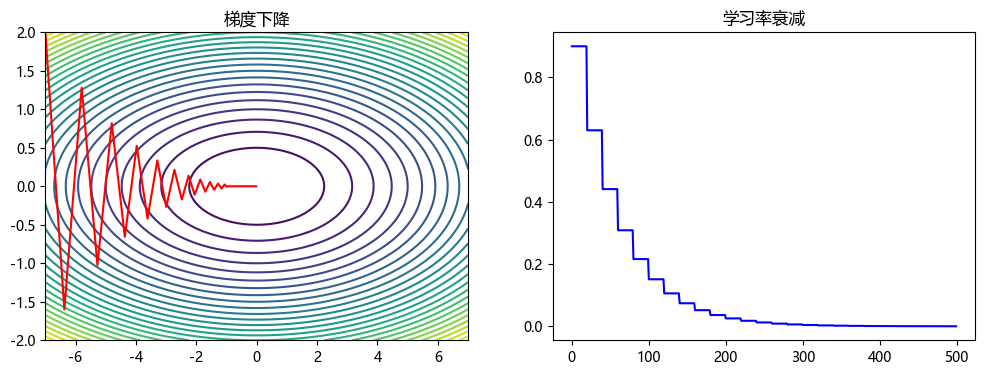

In [21]:
lr = 0.9
num_iters = 500

x_clone = x.clone().detach().requires_grad_(True)
optimizer = torch.optim.SGD([x_clone], lr=lr)
# 学习率衰减策略
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.7)

x_arr = x.detach().numpy().copy()
lr_list = []
for i in range(num_iters):
    # 前向传播
    y = f(x_clone)
    # 反向传播
    y.backward()
    # 更新参数
    optimizer.step()
    # 梯度清零
    optimizer.zero_grad()

    x_arr = np.vstack([x_arr, x_clone.detach().numpy()])
    # param_groups只有一个字典元素，所以是[0]
    lr_list.append(optimizer.param_groups[0]['lr'])

    # 更新学习率
    lr_scheduler.step()

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(1, 2, figsize=[12, 4])
x1_grid, x2_grid = np.meshgrid(np.linspace(-7, 7, 100), np.linspace(-2, 2, 100))
y_grid = 0.05 * (x1_grid ** 2) + x2_grid ** 2
ax[0].contour(x1_grid, x2_grid, y_grid, levels=30, color='gray')
ax[0].plot(x_arr[:, 0], x_arr[:, 1], 'r')
ax[0].set_title('梯度下降')

ax[1].plot(lr_list, 'b')
ax[1].set_title('学习率衰减')

plt.show()


# 指定间隔衰减

C:\Users\13175\AppData\Local\Temp\ipykernel_37472\922379084.py:40: UserWarning: The following kwargs were not used by contour: 'color'
  ax[0].contour(x1_grid, x2_grid, y_grid, levels=30, color='gray')


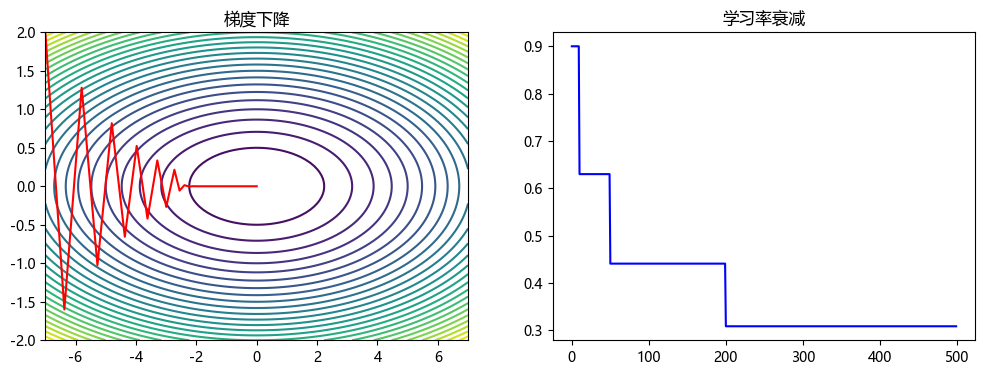

In [3]:
from torch.optim.lr_scheduler import MultiStepLR

# 定义函数
def f(x):
    return 0.05 * (x[0] ** 2) + x[1] ** 2

lr = 0.9
num_iters = 500
x = torch.tensor([-7.0, 2.0], requires_grad=True)

x_clone = x.clone().detach().requires_grad_(True)
optimizer = torch.optim.SGD([x_clone], lr=lr)
# 学习率衰减策略
lr_scheduler = MultiStepLR(optimizer, milestones=[10, 50, 200], gamma=0.7)

x_arr = x.detach().numpy().copy()
lr_list = []
for i in range(num_iters):
    # 前向传播
    y = f(x_clone)
    # 反向传播
    y.backward()
    # 更新参数
    optimizer.step()
    # 梯度清零
    optimizer.zero_grad()

    x_arr = np.vstack([x_arr, x_clone.detach().numpy()])
    # param_groups只有一个字典元素，所以是[0]
    lr_list.append(optimizer.param_groups[0]['lr'])

    # 更新学习率
    lr_scheduler.step()

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(1, 2, figsize=[12, 4])
x1_grid, x2_grid = np.meshgrid(np.linspace(-7, 7, 100), np.linspace(-2, 2, 100))
y_grid = 0.05 * (x1_grid ** 2) + x2_grid ** 2
ax[0].contour(x1_grid, x2_grid, y_grid, levels=30, color='gray')
ax[0].plot(x_arr[:, 0], x_arr[:, 1], 'r')
ax[0].set_title('梯度下降')

ax[1].plot(lr_list, 'b')
ax[1].set_title('学习率衰减')

plt.show()

C:\Users\13175\AppData\Local\Temp\ipykernel_37472\2508038345.py:40: UserWarning: The following kwargs were not used by contour: 'color'
  ax[0].contour(x1_grid, x2_grid, y_grid, levels=30, color='gray')


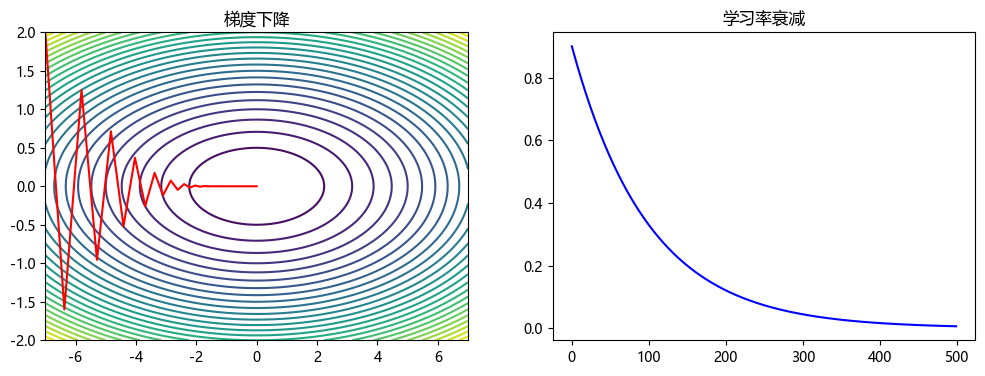

In [4]:
from torch.optim.lr_scheduler import ExponentialLR

# 定义函数
def f(x):
    return 0.05 * (x[0] ** 2) + x[1] ** 2

lr = 0.9
num_iters = 500
x = torch.tensor([-7.0, 2.0], requires_grad=True)

x_clone = x.clone().detach().requires_grad_(True)
optimizer = torch.optim.SGD([x_clone], lr=lr)
# 学习率衰减策略
lr_scheduler = ExponentialLR(optimizer, gamma=0.99)

x_arr = x.detach().numpy().copy()
lr_list = []
for i in range(num_iters):
    # 前向传播
    y = f(x_clone)
    # 反向传播
    y.backward()
    # 更新参数
    optimizer.step()
    # 梯度清零
    optimizer.zero_grad()

    x_arr = np.vstack([x_arr, x_clone.detach().numpy()])
    # param_groups只有一个字典元素，所以是[0]
    lr_list.append(optimizer.param_groups[0]['lr'])

    # 更新学习率
    lr_scheduler.step()

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(1, 2, figsize=[12, 4])
x1_grid, x2_grid = np.meshgrid(np.linspace(-7, 7, 100), np.linspace(-2, 2, 100))
y_grid = 0.05 * (x1_grid ** 2) + x2_grid ** 2
ax[0].contour(x1_grid, x2_grid, y_grid, levels=30, color='gray')
ax[0].plot(x_arr[:, 0], x_arr[:, 1], 'r')
ax[0].set_title('梯度下降')

ax[1].plot(lr_list, 'b')
ax[1].set_title('学习率衰减')

plt.show()